# ¿La música se volvió más enérgica y menos alegre? Argentina frente al mundo (1920–2021)

**TP Grupal · Laboratorio de Métodos Cuantitativos · FCE UBA · 2C 2026**

**Integrantes:** Sergio Sebastian Cordoba (921765) · Mauro Nohara Gushiken (922170) · Facundo Malpeli (921871) · Manuel Mariani (921739)

**Dataset:** [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks) (Kaggle, usuario *yamaerenay*). Usamos dos archivos:
- `tracks.csv`: una fila por canción, con su fecha de lanzamiento y sus características de audio.
- `artists.csv`: los artistas con los géneros que les asigna Spotify. Lo usamos para identificar la música argentina.

### Uso de IA
Las celdas marcadas con **[Asistido por IA]** se armaron con ayuda de Claude, en un proyecto que tenía como contexto las pautas del TP. Prompts utilizados:
- Sección 3.1: «como puedo explorar el dataset»
- Secciones 3.2 a 3.4: «¿La música se volvió más enérgica y menos alegre entre 1920 y 2021? ¿La música argentina siguió la misma tendencia que la global? podrías hacer el trabajo en base a eso? y adaptar lo que ya teníamos?»
- *(Agregar acá los prompts que se usen para las interpretaciones, si se usa IA.)*

## 3.1 Carga y exploración inicial

### a) Carga del dataset · [Asistido por IA]

Descargamos el dataset directamente desde Kaggle con la librería `kagglehub`, para que cualquiera pueda volver a correr el notebook sin subir archivos a mano.

> Si la descarga falla, se puede bajar el ZIP desde la página de Kaggle (requiere cuenta), subir `tracks.csv` y `artists.csv` a Colab y cargarlos con `pd.read_csv("tracks.csv")` y `pd.read_csv("artists.csv")`.

In [ ]:
%pip install -q kagglehub

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# Descarga el dataset y devuelve la carpeta donde quedaron los archivos
path = kagglehub.dataset_download("yamaerenay/spotify-dataset-19212020-600k-tracks")

df = pd.read_csv(path + "/tracks.csv")        # canciones
artists = pd.read_csv(path + "/artists.csv")  # artistas y sus géneros

# Colores fijos para todo el trabajo
COLORES = {"Argentina": "#2a78d6", "Resto": "#eb6834"}

Using Colab cache for faster access to the 'spotify-dataset-19212020-600k-tracks' dataset.


#### Primeras y últimas filas
Miramos el principio y el final de la tabla para ver cómo vienen los datos: qué tiene cada columna, ejemplos de valores y si hay algo raro a simple vista.

In [ ]:
display(df.head())
display(df.tail())

,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,['Uli'],['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,0,-13.338,1,0.4510,0.674,0.7440,0.151,0.127,104.851,3
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,['Fernando Pessoa'],['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,0,-22.136,1,0.9570,0.797,0.0000,0.148,0.655,102.009,1
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,1,-21.180,1,0.0512,0.994,0.0218,0.212,0.457,130.418,5
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,7,-27.961,1,0.0504,0.995,0.9180,0.104,0.397,169.980,3
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,['Dick Haymes'],['3BiJGZsyX9sJchTqcSA7Su'],1922,0.402,0.1580,3,-16.900,0,0.0390,0.989,0.1300,0.311,0.196,103.220,4


,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
586667,5rgu12WBIHQtvej2MdHSH0,云与海,50,258267,0,['阿YueYue'],['1QLBXKM5GCpyQQSVMNZqrZ'],2020-09-26,0.560,0.518,0,-7.471,0,0.0292,0.785,0.000000,0.0648,0.2110,131.896,4
586668,0NuWgxEp51CutD2pJoF4OM,blind,72,153293,0,['ROLE MODEL'],['1dy5WNgIKQU6ezkpZs4y8z'],2020-10-21,0.765,0.663,0,-5.223,1,0.0652,0.141,0.000297,0.0924,0.6860,150.091,4
586669,27Y1N4Q4U3EfDU5Ubw8ws2,What They'll Say About Us,70,187601,0,['FINNEAS'],['37M5pPGs6V1fchFJSgCguX'],2020-09-02,0.535,0.314,7,-12.823,0,0.0408,0.895,0.000150,0.0874,0.0663,145.095,4
586670,45XJsGpFTyzbzeWK8VzR8S,A Day At A Time,58,142003,0,"['Gentle Bones', 'Clara Benin']","['4jGPdu95icCKVF31CcFKbS', '5ebPSE9YI5aLeZ1Z2g...",2021-03-05,0.696,0.615,10,-6.212,1,0.0345,0.206,0.000003,0.3050,0.4380,90.029,4
586671,5Ocn6dZ3BJFPWh4ylwFXtn,Mar de Emociones,38,214360,0,['Afrosound'],['0i4Qda0k4nf7jnNHmSNpYv'],2015-07-01,0.686,0.723,6,-7.067,1,0.0363,0.105,0.000000,0.2640,0.9750,112.204,4


### b) Estructura: dimensiones, columnas y tipos de dato · [Asistido por IA]

Detalles a tener en cuenta:
- `release_date` es **texto**, no fecha: hay que convertirla para trabajar con años.
- `artists` e `id_artists` son textos con forma de lista, por ejemplo `"['Uli']"`.
- `explicit` y `mode` son 0/1, y `key` es un número de 0 a 11 que representa la nota (0 = Do).

In [ ]:
print("Filas (canciones):", df.shape[0])
print("Columnas:", df.shape[1])
df.dtypes

Filas (canciones): 586672
Columnas: 20


,0
id,object
name,object
popularity,int64
duration_ms,int64
explicit,int64
artists,object
id_artists,object
release_date,object
danceability,float64
energy,float64


#### Cobertura temporal
`release_date` no tiene siempre la misma precisión: algunas canciones solo tienen el año, otras año y mes, y otras la fecha completa. Contamos cuántas hay de cada tipo según la cantidad de caracteres y tomamos los primeros 4 para obtener el año.

El año se calcula acá solo para explorar; la columna definitiva se crea en la sección 3.3. El dataset **no tiene país**: la música argentina se identifica en la sección 3.3 a partir de los géneros de cada artista.

In [ ]:
# 4 caracteres = solo año, 7 = año y mes, 10 = fecha completa
precision = df["release_date"].str.len().map({4: "solo año", 7: "año y mes", 10: "fecha completa"})
print(precision.value_counts(dropna=False))

anio = df["release_date"].str[:4].astype(int)   # temporal, solo para explorar
print()
print("Año mínimo:", anio.min())
print("Año máximo:", anio.max())

release_date
fecha completa    448081
solo año          136489
año y mes           2102
Name: count, dtype: int64

Año mínimo: 1900
Año máximo: 2021


Contamos las canciones por década para ver si el dataset está balanceado en el tiempo.

In [ ]:
decada = (anio // 10) * 10
decada.value_counts().sort_index().rename("canciones")

,canciones
release_date,
1900,1
1920,7610
1930,13037
1940,18042
1950,35370
1960,47270
1970,61841
1980,82322
1990,108875


Lo graficamos por año. Si las primeras décadas tienen pocas canciones, sus promedios van a ser menos confiables.

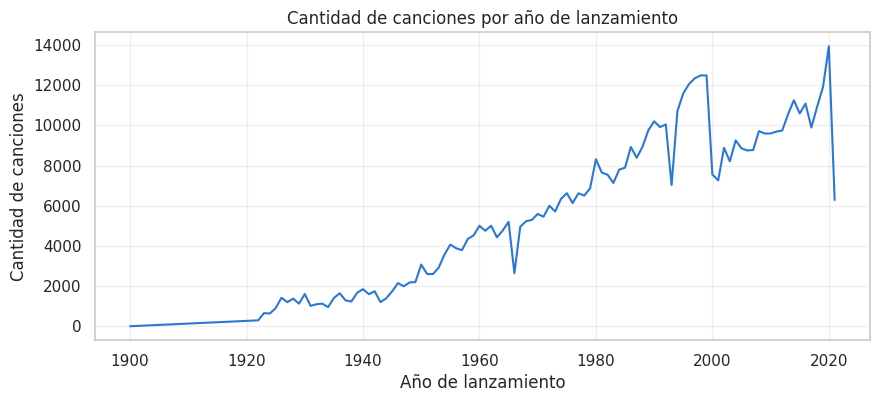

In [ ]:
anio.value_counts().sort_index().plot(figsize=(10, 4), color="#2a78d6")
plt.title("Cantidad de canciones por año de lanzamiento")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Cantidad de canciones")
plt.grid(alpha=0.3)
plt.show()

#### El archivo de artistas
Revisamos cuántos artistas hay y qué proporción no tiene ningún género asignado, porque de los géneros depende identificar la música argentina.

In [ ]:
print("Artistas:", artists.shape[0])
sin_genero = (artists["genres"] == "[]").mean() * 100
print(f"Artistas sin género asignado: {sin_genero:.1f} %")
artists.head()

Artistas: 1162095
Artistas sin género asignado: 73.7 %


,id,followers,genres,name,popularity
0,0DheY5irMjBUeLybbCUEZ2,0.0,[],Armid & Amir Zare Pashai feat. Sara Rouzbehani,0
1,0DlhY15l3wsrnlfGio2bjU,5.0,[],ปูนา ภาวิณี,0
2,0DmRESX2JknGPQyO15yxg7,0.0,[],Sadaa,0
3,0DmhnbHjm1qw6NCYPeZNgJ,0.0,[],Tra'gruda,0
4,0Dn11fWM7vHQ3rinvWEl4E,2.0,[],Ioannis Panoutsopoulos,0


### c) Calidad de los datos · [Asistido por IA]

#### Valores nulos

In [ ]:
df.isnull().sum()

,0
id,0
name,71
popularity,0
duration_ms,0
explicit,0
artists,0
id_artists,0
release_date,0
danceability,0
energy,0


#### Duplicados
Los revisamos en tres niveles:
1. **Filas idénticas.**
2. **IDs repetidos.**
3. **Misma canción y artista** con distinto `id`: suelen ser reediciones, remasters o compilados. Importan para nuestra pregunta, porque una canción de 1965 reeditada en 2010 aparece con fecha de 2010.

In [ ]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())
print("Misma canción y artista repetidos:", df.duplicated(subset=["name", "artists"]).sum())

Filas completamente duplicadas: 0
IDs repetidos: 0
Misma canción y artista repetidos: 60062


In [ ]:
# Las 5 combinaciones canción + artista que más se repiten
repetidas = df[df.duplicated(subset=["name", "artists"], keep=False)]
repetidas.groupby(["name", "artists"]).size().sort_values(ascending=False).head(5)

,,0
name,artists,
Year 3000,['Busted'],54
Hold On,['Justin Bieber'],47
Anyone,['Justin Bieber'],44
No Es Justo,"['J Balvin', 'Zion & Lennox']",42
Azul,['J Balvin'],42


#### Estadísticas descriptivas
Resumen de las columnas numéricas, transpuesto (`.T`) para que cada variable quede en una fila.

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
popularity,586672.0,27.57,18.37,0.0,13.00,27.00,41.00,100.00
duration_ms,586672.0,230051.17,126526.09,3344.0,175093.00,214893.00,263867.00,5621218.00
explicit,586672.0,0.04,0.21,0.0,0.00,0.00,0.00,1.00
danceability,586672.0,0.56,0.17,0.0,0.45,0.58,0.69,0.99
energy,586672.0,0.54,0.25,0.0,0.34,0.55,0.75,1.00
key,586672.0,5.22,3.52,0.0,2.00,5.00,8.00,11.00
loudness,586672.0,-10.21,5.09,-60.0,-12.89,-9.24,-6.48,5.38
mode,586672.0,0.66,0.47,0.0,0.00,1.00,1.00,1.00
speechiness,586672.0,0.10,0.18,0.0,0.03,0.04,0.08,0.97
acousticness,586672.0,0.45,0.35,0.0,0.10,0.42,0.78,1.00


#### Valores sospechosos
- `tempo = 0` o `time_signature = 0`: Spotify no pudo medir el ritmo.
- `speechiness > 0.66`: según Spotify, es audio casi todo hablado (audiolibros, poesía, discursos).
- Duraciones extremas.

In [ ]:
print("Canciones con tempo = 0:", (df["tempo"] == 0).sum())
print("Canciones con time_signature = 0:", (df["time_signature"] == 0).sum())
print("Canciones con popularidad = 0:", (df["popularity"] == 0).sum())
print("Grabaciones casi solo habladas (speechiness > 0.66):", (df["speechiness"] > 0.66).sum())
print("Canciones de más de 20 minutos:", (df["duration_ms"] > 20 * 60 * 1000).sum())
print("Canciones de menos de 30 segundos:", (df["duration_ms"] < 30 * 1000).sum())

Canciones con tempo = 0: 328
Canciones con time_signature = 0: 337
Canciones con popularidad = 0: 44690
Grabaciones casi solo habladas (speechiness > 0.66): 22598
Canciones de más de 20 minutos: 1089
Canciones de menos de 30 segundos: 228


In [ ]:
# Ejemplos de las grabaciones más "habladas": ¿son música o no?
(df[df["speechiness"] > 0.66]
   .sort_values("speechiness", ascending=False)
   [["name", "artists", "release_date", "speechiness"]]
   .head(10))

,name,artists,release_date,speechiness
482360,"Wer die Nachtigall stört ..., Kapitel 6","['Harper Lee', 'Eva Mattes']",1960,0.971
482422,"Wer die Nachtigall stört ..., Kapitel 98","['Harper Lee', 'Eva Mattes']",1960,0.971
324123,"Wer die Nachtigall stört ..., Kapitel 1","['Harper Lee', 'Eva Mattes']",1960,0.971
25842,Kapitel 16 - Der alte Mann und das Meer - Erzä...,"['Ernest Hemingway', 'Christian Brückner']",1952,0.970
25839,Kapitel 15 - Der alte Mann und das Meer - Erzä...,"['Ernest Hemingway', 'Christian Brückner']",1952,0.970
482383,"Wer die Nachtigall stört ..., Kapitel 12","['Harper Lee', 'Eva Mattes']",1960,0.970
482472,"Wer die Nachtigall stört ..., Kapitel 147","['Harper Lee', 'Eva Mattes']",1960,0.970
493349,"Wer die Nachtigall stört ..., Kapitel 105","['Harper Lee', 'Eva Mattes']",1960,0.970
493342,"Wer die Nachtigall stört ..., Kapitel 95","['Harper Lee', 'Eva Mattes']",1960,0.970
482444,"Wer die Nachtigall stört ..., Kapitel 128","['Harper Lee', 'Eva Mattes']",1960,0.970


### Hallazgos de la exploración · [Asistido por IA] *(revisar)*

- **Tamaño:** 586.672 canciones y 20 columnas.
- **Cobertura temporal:** de 1900 a 2021, pero 1900 tiene una sola canción y la década de 2020 solo incluye 2020 y 2021. La cantidad de canciones crece mucho con el tiempo (7.610 en los años 20 contra 108.875 en los 90), así que los promedios de las primeras décadas son menos estables.
- **Fechas:** el 23,3 % de las canciones solo tiene el año (136.489), por eso trabajamos con el año y no con la fecha completa.
- **Nulos:** solo en `name` (71 canciones, 0,01 %). No afectan a las variables de audio.
- **Duplicados:** no hay filas ni IDs repetidos, pero 60.062 canciones (10,2 %) repiten nombre y artista: son reediciones y compilados que pueden tener fechas posteriores a la original.
- **Valores raros:** 22.598 grabaciones casi solo habladas (3,9 %). Las más extremas son audiolibros en alemán fechados en 1952 y 1960, el año de publicación del libro y no el de la grabación, lo que muestra que la fecha no siempre es confiable. También hay 328 canciones con tempo 0 y 228 de menos de 30 segundos.
- **Artistas:** *(completar con el % sin género que muestra la celda de artistas)*.
- **Decisiones para la sección 3.3:** trabajar desde 1920, excluir grabaciones habladas y muy cortas, eliminar reediciones y cruzar con los artistas para identificar la música argentina.

## 3.2 Pregunta de investigación · [Asistido por IA]

**a) ¿Cuál es la pregunta?**

¿La música se volvió más enérgica y menos alegre entre 1920 y 2021? ¿La música argentina siguió la misma tendencia que la global?

Para responderla usamos dos atributos que Spotify calcula para cada canción:
- **`energy`** (energía, de 0 a 1): qué tan intensa y activa suena la canción.
- **`valence`** (valencia, de 0 a 1): qué tan positiva o alegre suena. Valores altos son canciones alegres; valores bajos, tristes o tensas.

**b) ¿Por qué vale la pena responderla?**

La música refleja los cambios culturales y tecnológicos de cada época. Estudios previos encontraron que la música popular se volvió más negativa en las últimas décadas (Brand, Acerbi y Mesoudi, 2019; Interiano et al., 2018). Esta pregunta permite contrastar esa tendencia a lo largo de un siglo y analizar si la música argentina se fue pareciendo a la global o si conserva un perfil propio. La respuesta es útil para la industria musical, porque ayuda a decidir qué producir y para qué público, y para el diseño de políticas culturales de fomento de la música nacional.

**c) ¿Qué respuesta encontraron?**

Para responder si la música se volvió más enérgica y menos alegre, comparamos los promedios de energía y valencia entre las décadas de 1920 y 2010. La energía aumentó tanto en las canciones clasificadas como argentinas —de 0,227 a 0,703— como en el resto de la muestra —de 0,334 a 0,656—. La valencia, en cambio, disminuyó en ambos grupos: de 0,702 a 0,651 en Argentina y de 0,588 a 0,512 en el resto. Por lo tanto, en el período analizado, ambos grupos siguieron la tendencia planteada, aunque el aumento de energía fue mayor en las canciones clasificadas como argentinas y la caída de valencia fue mayor en el resto de la muestra. Estos resultados describen atributos de las canciones del dataset y no miden directamente las preferencias de los oyentes.

## 3.3 Transformaciones y resumen estadístico

### a) Transformaciones justificadas · [Asistido por IA]

1. **Año y década de lanzamiento.** `release_date` mezcla formatos, así que tomamos los primeros 4 caracteres como año y agrupamos por década, que suaviza el ruido de los años con pocas canciones.
2. **Filtro de filas.** Excluimos:
   - las canciones anteriores a 1920 (en 1900 hay una sola, que distorsionaría los promedios);
   - las grabaciones casi solo habladas (`speechiness > 0.66`), porque no son música;
   - las pistas de menos de 30 segundos (intros, separadores);
   - las 71 canciones sin nombre, que no se pueden controlar como duplicadas.
3. **Eliminación de reediciones.** Cuando una canción aparece varias veces con el mismo nombre y artista, nos quedamos con la de fecha más antigua, que es la más cercana al lanzamiento original.
4. **Origen de la música (Argentina / Resto).** Cruzamos cada canción con su artista principal en `artists.csv` y la marcamos como argentina si alguno de sus géneros es argentino.

In [ ]:
# 1) Año y década
df["year"] = df["release_date"].str[:4].astype(int)
df["decada"] = (df["year"] // 10) * 10

# 2) Filtro de filas
df_analisis = df[
    (df["year"] >= 1920)
    & (df["speechiness"] <= 0.66)
    & (df["duration_ms"] >= 30_000)
    & (df["name"].notna())
].copy()
print(f"Canciones originales:        {len(df):,}")
print(f"Después de filtrar:          {len(df_analisis):,}")

# 3) Reediciones: nos quedamos con la versión más antigua de cada canción + artista
antes = len(df_analisis)
df_analisis = (df_analisis.sort_values("year")
                          .drop_duplicates(subset=["name", "artists"], keep="first")
                          .copy())
print(f"Reediciones eliminadas:      {antes - len(df_analisis):,}")
print(f"Canciones para el análisis:  {len(df_analisis):,}")

Canciones originales:        586,672
Después de filtrar:          563,806
Reediciones eliminadas:      59,776
Canciones para el análisis:  504,030


#### Identificación de la música argentina
Spotify asigna géneros a los artistas, no a las canciones. Usamos los géneros del **artista principal** (el primero de `id_artists`) y consideramos argentina una canción si alguno de esos géneros contiene alguna de estas palabras: *argentin, tango, rock nacional, cuarteto, chamame, cumbia villera, rkt*. Dejamos afuera "finnish tango" (tango finlandés) y "rock nacional brasileiro".

In [ ]:
# Primer artista de cada canción: "['id1', 'id2']" -> "id1"
df_analisis["id_artista"] = (df_analisis["id_artists"]
                             .str.strip("[]").str.split(", ").str[0].str.strip("'"))

# Le pegamos los géneros de su artista (las canciones sin artista encontrado quedan con "[]")
df_analisis = df_analisis.merge(
    artists[["id", "genres"]].rename(columns={"id": "id_artista"}),
    on="id_artista", how="left")
df_analisis["genres"] = df_analisis["genres"].fillna("[]")

# Texto "['tango', 'vintage tango']" -> lista ['tango', 'vintage tango']
df_analisis["generos"] = (df_analisis["genres"].str.strip("[]")
                          .str.replace("'", "").str.replace('"', "")
                          .str.split(", "))

# 4) Origen
CLAVES_ARG = ["argentin", "tango", "rock nacional", "cuarteto", "chamame", "cumbia villera", "rkt"]
EXCLUIR = ["finnish", "brasileiro"]

def es_argentina(generos):
    return any(any(c in g for c in CLAVES_ARG) and not any(e in g for e in EXCLUIR) for g in generos)

df_analisis["origen"] = np.where(df_analisis["generos"].apply(es_argentina), "Argentina", "Resto")
df_analisis["origen"].value_counts()

,count
origen,
Resto,492132
Argentina,11898


**Control:** listamos los géneros que entraron como argentinos para verificar que no se haya colado ninguno de otro país. Si aparece alguno, se agrega a `EXCLUIR` y se vuelve a correr la celda anterior.

In [ ]:
generos_arg = df_analisis.loc[df_analisis["origen"] == "Argentina", "generos"].explode()
generos_arg = generos_arg[generos_arg.str.contains("|".join(CLAVES_ARG))]
generos_arg.value_counts().head(30)

,count
generos,
argentine rock,4903
rock nacional,3474
tango,2941
vintage tango,2720
folklore argentino,1738
cumbia villera,1331
ska argentino,1000
chamame,871
post-punk argentina,720


**Cantidad de canciones por década y origen.** Para que un promedio sea confiable pedimos un mínimo de 100 canciones; las décadas que no lleguen quedan fuera de las comparaciones. La década de 2020 solo tiene 2020 y 2021, así que para medir cambios usamos como última década **2010**, la última completa.

In [ ]:
MIN_CANCIONES = 100
DECADA_FINAL = 2010   # última década completa

conteo = df_analisis.groupby(["decada", "origen"]).size().unstack(fill_value=0)
display(conteo)

# Primera década en que Argentina tiene suficientes canciones: es el punto de partida de la comparación
DECADA_INICIAL = int(conteo.index[conteo["Argentina"] >= MIN_CANCIONES].min())
print(f"Comparamos desde los {DECADA_INICIAL} hasta los {DECADA_FINAL}.")

origen,Argentina,Resto
decada,,
1920,1344,3591
1930,983,9202
1940,279,14940
1950,96,30622
1960,602,41494
1970,1017,52788
1980,1263,66912
1990,2502,91043
2000,2134,72244


Comparamos desde los 1920 hasta los 2010.


### b) Estadísticos agrupados con `.groupby()` · [Asistido por IA]

**Resumen 1: evolución global por década.** Promedio de energía, valence, acusticidad y bailabilidad de todas las canciones de cada década.

In [ ]:
ATRIBUTOS = ["energy", "valence", "acousticness", "danceability"]
NOMBRES = {"energy": "Energía", "valence": "Valence (alegría)",
           "acousticness": "Acusticidad", "danceability": "Bailabilidad"}

resumen_global = df_analisis.groupby("decada").agg(
    canciones=("energy", "size"),
    **{a: (a, "mean") for a in ATRIBUTOS}
).round(3)
resumen_global

,canciones,energy,valence,acousticness,danceability
decada,,,,,
1920,4935,0.305,0.619,0.950,0.577
1930,10185,0.315,0.573,0.920,0.531
1940,15219,0.273,0.499,0.916,0.472
1950,30718,0.302,0.493,0.845,0.474
1960,42096,0.406,0.564,0.680,0.495
1970,53805,0.502,0.583,0.491,0.517
1980,68175,0.561,0.582,0.388,0.553
1990,93545,0.579,0.569,0.358,0.568
2000,74378,0.651,0.565,0.312,0.590


**Resumen 2: Argentina frente al resto, por década.** Los mismos promedios separados por origen. Las décadas con menos de 100 canciones aparecen vacías.

In [ ]:
por_origen = df_analisis.groupby(["decada", "origen"]).agg(
    canciones=("energy", "size"),
    **{a: (a, "mean") for a in ATRIBUTOS}
).reset_index()
por_origen.loc[por_origen["canciones"] < MIN_CANCIONES, ATRIBUTOS] = np.nan

por_origen.pivot(index="decada", columns="origen", values=["canciones", "energy", "valence"]).round(3)

canciones             energy          valence       
origen Argentina    Resto Argentina  Resto Argentina  Resto
decada                                                     
1920      1344.0   3591.0     0.227  0.334     0.702  0.588
1930       983.0   9202.0     0.308  0.316     0.759  0.554
1940       279.0  14940.0     0.327  0.272     0.705  0.495
1950        96.0  30622.0       NaN  0.301       NaN  0.493
1960       602.0  41494.0     0.423  0.406     0.556  0.564
1970      1017.0  52788.0     0.427  0.504     0.489  0.584
1980      1263.0  66912.0     0.586  0.560     0.573  0.582
1990      2502.0  91043.0     0.641  0.577     0.616  0.568
2000      2134.0  72244.0     0.718  0.649     0.665  0.562
2010      1546.0  92275.0     0.703  0.656     0.651  0.512
2020       132.0  17021.0     0.650  0.625     0.621  0.489

**Resumen 3: cuánto cambió cada atributo.** Diferencia entre la década inicial y la final, para cada origen. Un valor positivo indica que el atributo aumentó.

In [ ]:
inicio = por_origen[por_origen["decada"] == DECADA_INICIAL].set_index("origen")[ATRIBUTOS]
final = por_origen[por_origen["decada"] == DECADA_FINAL].set_index("origen")[ATRIBUTOS]
cambios = (final - inicio).T.rename(index=NOMBRES).round(3)

print(f"Cambio entre los {DECADA_INICIAL} y los {DECADA_FINAL} (valor final − valor inicial):")
cambios

Cambio entre los 1920 y los 2010 (valor final − valor inicial):


origen,Argentina,Resto
Energía,0.476,0.322
Valence (alegría),-0.051,-0.075
Acusticidad,-0.720,-0.644
Bailabilidad,-0.003,0.055


**Interpretación de los resúmenes** *(completar después de ejecutar)*

- **Tendencia global:** la energía pasó de ___ en los años 20 a ___ en los 2010, y la valence de ___ a ___. ¿La música se volvió más enérgica? ¿Y menos alegre? ¿Los dos cambios ocurren al mismo tiempo o en épocas distintas?
- **Argentina:** ¿la energía y la valence argentinas se movieron en la misma dirección que el resto? ¿El cambio fue más grande o más chico (ver Resumen 3)?
- **Década clave:** ¿en qué década se ve el salto más grande? ¿Qué cambios tecnológicos o culturales coinciden con ese momento?

## 3.4 Análisis gráfico · [Asistido por IA]

### Gráfico 1: evolución temporal de la energía y la alegría
Dos paneles con la misma escala: la energía a la izquierda y la valence a la derecha, cada uno con una línea para la música argentina y otra para el resto.

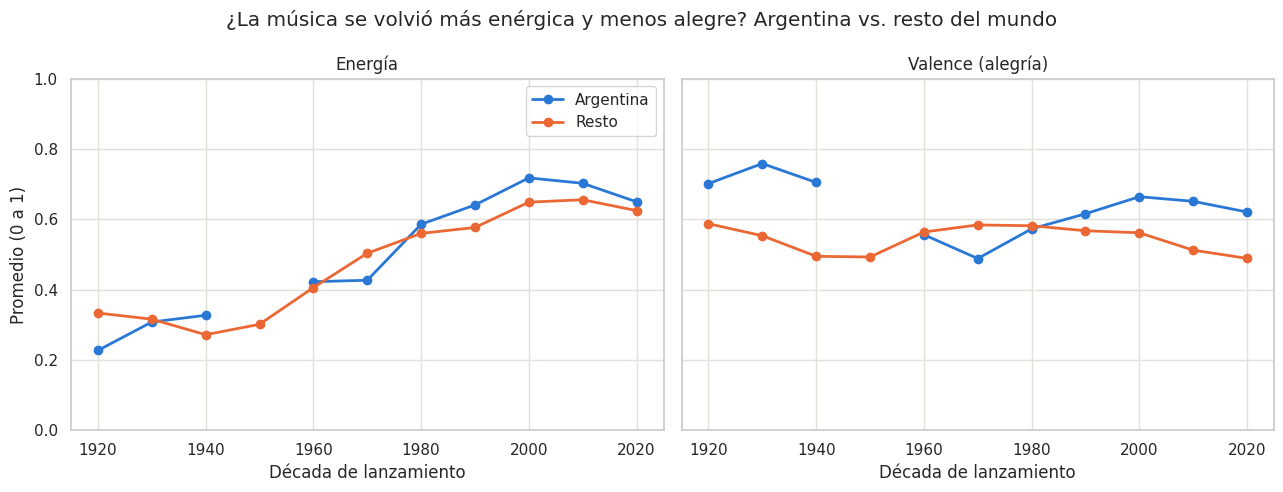

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, var in zip(ejes, ["energy", "valence"]):
    for origen in ["Argentina", "Resto"]:
        datos = por_origen[por_origen["origen"] == origen]
        ax.plot(datos["decada"], datos[var], marker="o", linewidth=2,
                color=COLORES[origen], label=origen)
    ax.set_title(NOMBRES[var])
    ax.set_xlabel("Década de lanzamiento")
    ax.set_ylim(0, 1)
    ax.grid(color="#e1e0d9")
    ax.set_axisbelow(True)
ejes[0].set_ylabel("Promedio (0 a 1)")
ejes[0].legend()
fig.suptitle("¿La música se volvió más enérgica y menos alegre? Argentina vs. resto del mundo")
plt.tight_layout()
plt.savefig("grafico1_energia_valence_por_decada.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretación**:
La energía de las canciones clasificadas como argentinas comienza a aumentar entre las décadas de 1920 y 1930. En el resto de la muestra disminuye hasta los años 40 y luego empieza a crecer. La tendencia ascendente se vuelve más marcada en ambos grupos desde los años 60 y 70, aunque la energía del resto supera a la argentina en los 70; desde los 80, la media argentina vuelve a ubicarse por encima. En conjunto, la energía aumentó entre las décadas inicial y final en ambos grupos.

La valencia no disminuye de manera continua. En Argentina sube en los años 30, cae hasta los 70 y se recupera durante las décadas siguientes, con una leve baja en los 2010. En el resto de la muestra baja hasta los 50, aumenta hasta los 70 y luego desciende. Aun con esos cambios intermedios, en los 2010 la valencia media es menor que en los 1920 en ambos grupos.

Por lo tanto, las dos tendencias generales planteadas aparecen al comparar los extremos del período: mayor energía y menor valencia. Sin embargo, las trayectorias no son idénticas ni ocurren al mismo ritmo. La línea argentina no sigue siempre por delante o por detrás: la diferencia cambia según la década. La comparación de los años 50 en Argentina no está disponible porque sus 96 canciones quedan por debajo del mínimo de 100 establecido para graficar promedios.

#### El quiebre y divergencia entre 1970 y 2010
Al acotar el análisis al período comprendido entre **1970 y 2010**, se observa el fenómeno más contrastante del estudio: mientras que los niveles de energía crecen de manera sostenida en ambos grupos, la **valencia** diverge de forma abrupta, mostrando una caída en el promedio global frente a un incremento sostenido en la música argentina.

* **En energía:** Argentina pasó de 0,427 a 0,703 (+0,276), acompañando la tendencia del resto del mundo, que subió de 0,504 a 0,656 (+0,152).
* **En valencia:** El resto del mundo registró una caída constante década a década (0,584 → 0,512, con un descenso de −0,072), mientras que la música argentina experimentó un incremento sostenido (0,489 → 0,651, ganando +0,162).

In [ ]:
# Análisis específico y compacto del período 1970-2010
df_70_10 = df_analisis[(df_analisis['decada'] >= 1970) & (df_analisis['decada'] <= 2010)]
resumen_70_10 = df_70_10.groupby(['decada', 'origen']).agg(
    energy=('energy', 'mean'),
    valence=('valence', 'mean')
).unstack()

display(resumen_70_10.round(3))

energy          valence       
origen Argentina  Resto Argentina  Resto
decada                                  
1970       0.427  0.504     0.489  0.584
1980       0.586  0.560     0.573  0.582
1990       0.641  0.577     0.616  0.568
2000       0.718  0.649     0.665  0.562
2010       0.703  0.656     0.651  0.512

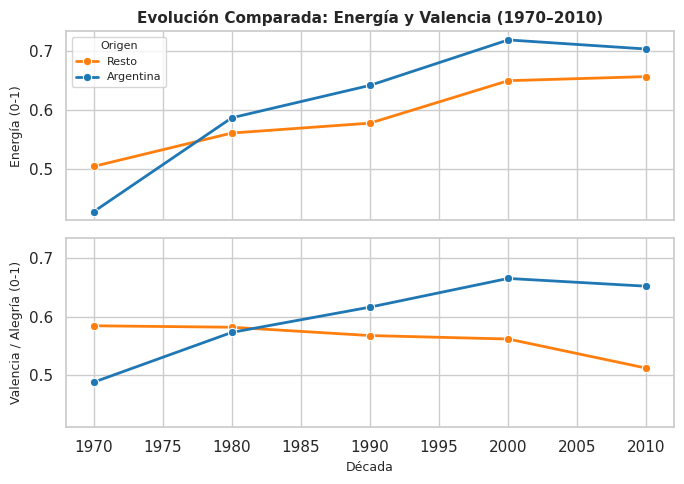

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Definimos la paleta con los colores consistentes (Argentina = Celeste/Azul, Resto = Naranja)
paleta_colores = {
    'Argentina': '#1f77b4',
    'Resto': '#ff7f0e'
}

# Creación del gráfico unificado con la misma escala en Y (sharey=True)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True, sharey=True)

# Subgráfico superior: Energía (1970-2010)
sns.lineplot(
    data=df_70_10, x='decada', y='energy', hue='origen',
    marker='o', errorbar=None, ax=axes[0], palette=paleta_colores, linewidth=2
)
axes[0].set_title("Evolución Comparada: Energía y Valencia (1970–2010)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Energía (0-1)", fontsize=9)
axes[0].legend(title="Origen", fontsize=8, title_fontsize=8)

# Subgráfico inferior: Valencia (1970-2010)
sns.lineplot(
    data=df_70_10, x='decada', y='valence', hue='origen',
    marker='o', errorbar=None, ax=axes[1], palette=paleta_colores, linewidth=2
)
axes[1].set_xlabel("Década", fontsize=9)
axes[1].set_ylabel("Valencia / Alegría (0-1)", fontsize=9)
axes[1].legend().remove()

plt.tight_layout()
plt.savefig("divergencia_70_10_integrado.png", dpi=300, bbox_inches='tight')
plt.show()

### Interpretación del hallazgo
El gráfico evidencia con claridad que en términos de **energía**, la música argentina acompañó exactamente el patrón global. Sin embargo, en términos de **valencia**, la música argentina no replicó la tendencia global hacia tonos más melancólicos o sombríos, sino que transitó un camino propio de mayor positividad y alegría a lo largo de esas cuatro décadas.

### Gráfico 2: cuánto cambió cada atributo, Argentina vs. resto
Barras con la diferencia entre la década inicial y la de 2010 para cada atributo. Si las barras de los dos colores van en la misma dirección y tienen un tamaño parecido, la música argentina siguió la tendencia global.

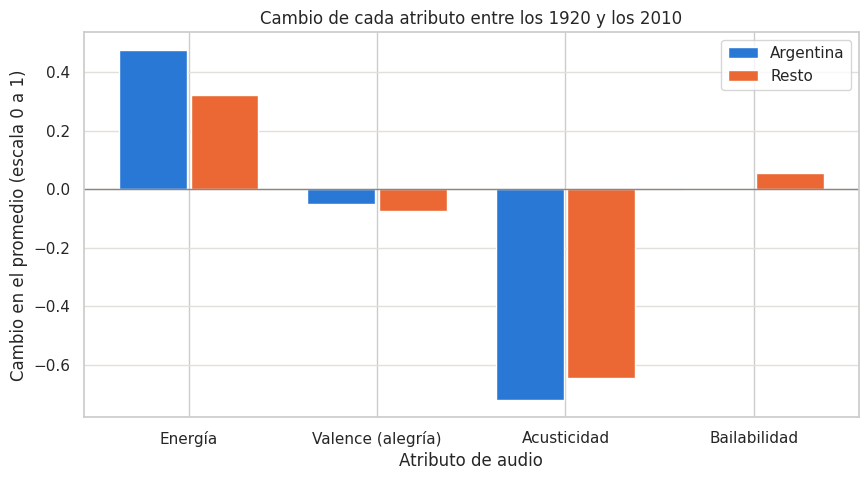

In [ ]:
x = np.arange(len(cambios))
ancho = 0.36
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.19, cambios["Argentina"], ancho, color=COLORES["Argentina"], label="Argentina")
ax.bar(x + 0.19, cambios["Resto"], ancho, color=COLORES["Resto"], label="Resto")
ax.axhline(0, color="#898781", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(cambios.index)
ax.set_title(f"Cambio de cada atributo entre los {DECADA_INICIAL} y los {DECADA_FINAL}")
ax.set_xlabel("Atributo de audio")
ax.set_ylabel("Cambio en el promedio (escala 0 a 1)")
ax.legend()
ax.grid(axis="y", color="#e1e0d9")
ax.set_axisbelow(True)
plt.savefig("grafico2_cambio_por_atributo.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretación**:
Entre las décadas de 1920 y 2010, la energía aumentó y la acusticidad disminuyó tanto en las canciones clasificadas como argentinas como en el resto de la muestra. El aumento de energía fue mayor en Argentina (+0,476 frente a +0,322), mientras que la caída de acusticidad también fue algo más pronunciada en ese grupo (−0,720 frente a −0,644). La valencia disminuyó en ambos grupos, con una caída mayor en el resto (−0,075 frente a −0,051). La bailabilidad fue la excepción: casi no varió en Argentina (−0,003) y aumentó en el resto (+0,055). En síntesis, los grupos compartieron la dirección del cambio en energía, valencia y acusticidad, pero no en bailabilidad; la intensidad de los cambios también fue diferente.

### Gráfico 3: mapa de ánimo (relación entre energía y valence)
Cruzamos las dos variables de la pregunta. Cada punto es el promedio de una década y la línea muestra el recorrido en el tiempo. Los cuadrantes ayudan a leer el "ánimo" de la música: alegre y enérgica, tensa, triste o tranquila.

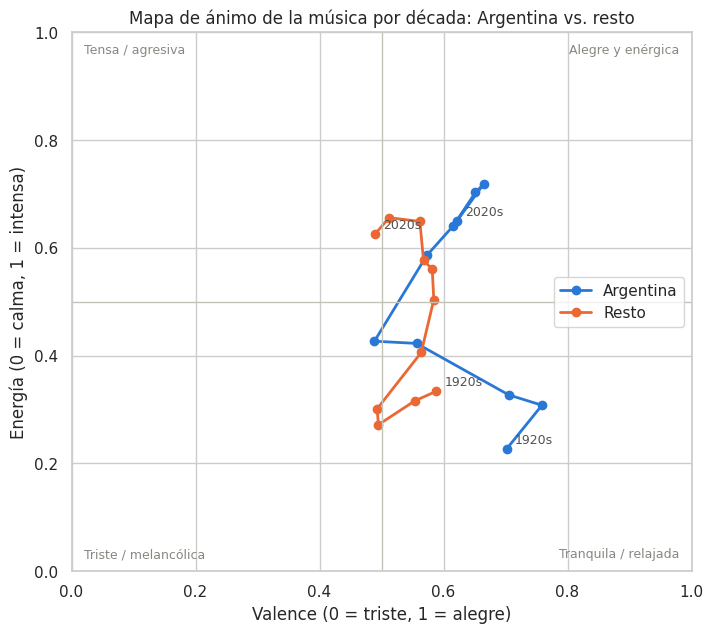

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
for origen in ["Argentina", "Resto"]:
    datos = por_origen[por_origen["origen"] == origen].dropna(subset=["valence", "energy"])
    ax.plot(datos["valence"], datos["energy"], marker="o", linewidth=2,
            color=COLORES[origen], label=origen)
    for _, fila in datos.iloc[[0, -1]].iterrows():   # rotulamos la primera y la última década
        ax.annotate(f"{int(fila['decada'])}s", (fila["valence"], fila["energy"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=9, color="#52514e")

ax.axvline(0.5, color="#c3c2b7", linewidth=1)
ax.axhline(0.5, color="#c3c2b7", linewidth=1)
for x_txt, y_txt, texto in [(0.98, 0.98, "Alegre y enérgica"), (0.02, 0.98, "Tensa / agresiva"),
                            (0.02, 0.02, "Triste / melancólica"), (0.98, 0.02, "Tranquila / relajada")]:
    ax.text(x_txt, y_txt, texto, transform=ax.transAxes,
            ha="right" if x_txt > 0.5 else "left", va="top" if y_txt > 0.5 else "bottom",
            fontsize=9, color="#898781")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Mapa de ánimo de la música por década: Argentina vs. resto")
ax.set_xlabel("Valence (0 = triste, 1 = alegre)")
ax.set_ylabel("Energía (0 = calma, 1 = intensa)")
ax.legend(loc="center right")
plt.savefig("grafico3_mapa_de_animo.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretación**:
Al comparar los promedios de las décadas de 1920 y 2010, ambos grupos se desplazaron del cuadrante de música tranquila/relajada al de música alegre y enérgica. En los dos aumentó la energía y disminuyó la valencia, aunque esta última se mantuvo por encima de 0,5 en la década final. Por eso, ninguno terminó en el cuadrante tenso, que combina energía superior a 0,5 con valencia inferior a 0,5. Los recorridos no fueron idénticos: la energía aumentó más en Argentina, y la valencia tuvo fluctuaciones distintas en cada grupo. El gráfico resume promedios por década; no significa que todas las canciones del grupo compartan esas características.

## Limitaciones · [Asistido por IA] *(revisar)*

- **Fechas:** aun eliminando reediciones, algunas canciones conservan la fecha de una edición posterior (ver los audiolibros fechados con el año del libro).
- **Atributos estimados:** energy y valence son estimaciones de un algoritmo de Spotify, no mediciones. Valence es la más subjetiva.
- **Tecnología de grabación:** las grabaciones antiguas (mono, con ruido, de bajo volumen) pueden medir menos energía por la tecnología y no solo por la música.
- **Música argentina:** se define por los géneros del artista, que Spotify asignó hoy. Quedan afuera los artistas sin género y los argentinos etiquetados con géneros genéricos (por ejemplo, "latin pop"); el tango uruguayo cuenta como argentino.
- **Catálogo:** lo que está en Spotify no representa toda la música de cada época, sobre todo en las primeras décadas.

## Conclusión
En las canciones analizadas, entre las décadas de 1920 y 2010 aumentó el promedio de energía y disminuyó el de valencia. En el conjunto de canciones, la energía pasó de 0,305 a 0,657 y la valencia de 0,619 a 0,515. La tendencia general también se observa en ambos grupos: en las canciones clasificadas como argentinas, la energía aumentó de 0,227 a 0,703 y la valencia disminuyó de 0,702 a 0,651; en el resto de la muestra, pasaron de 0,334 a 0,656 y de 0,588 a 0,512, respectivamente. Así, la energía aumentó más en el grupo argentino, mientras que la caída de valencia fue mayor en el resto. La tendencia, sin embargo, no fue uniforme en todas las décadas.  

Estos resultados describen atributos de las canciones incluidas en el dataset y no permiten afirmar directamente qué preferían los oyentes ni generalizar a toda la música de cada época. La valencia se usa como aproximación a la positividad percibida, y la clasificación de Argentina se basa en géneros asociados al artista principal. Además, la comparación entre extremos llega a la década de 2010: la de 2020 está incompleta y no se incluyó en el cálculo principal. Por ello, sería más preciso presentar el período analizado como décadas de 1920 a 2010, no como 1920–2021.

Los cambios observados podrían relacionarse con la transformación de los géneros presentes en el catálogo y con cambios históricos en las tecnologías y prácticas de grabación y producción. Sin embargo, este análisis no permite identificar cuál de esos factores explica los resultados ni establecer una relación causal. Además, energy y valence son atributos estimados de las canciones: la menor valencia promedio no implica necesariamente que los oyentes estuvieran más tristes. Una extensión posible sería comparar estas tendencias dentro de cada género para evaluar cuánto se deben a cambios en los estilos representados y cuánto a cambios dentro de cada estilo.